JS06 Tugas: Multiple Linear Regression - Medical Cost Personal (insurance.csv).

Fitur: age, sex, bmi, children, smoker, region -> target: charges.
Dibandingkan dengan SVR (non-linier) dan regresi polinomial derajat 2.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("multiple_linear_regression.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-regresi\tugas


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

BASE = Path(__file__).resolve().parent
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)
CAT = ["sex", "smoker", "region"]
NUM = ["age", "bmi", "children"]

df = pd.read_csv(BASE.parent / "data" / "insurance.csv")
print("shape:", df.shape)
print(df.describe().T.round(2).to_string())
print("\nkorelasi dengan charges:\n",
      df.corr(numeric_only=True)["charges"].round(3).to_string())

X, y = df[NUM + CAT], df["charges"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

shape: (1338, 7)
           count      mean       std      min      25%      50%       75%       max
age       1338.0     39.21     14.05    18.00    27.00    39.00     51.00     64.00
bmi       1338.0     30.66      6.10    15.96    26.30    30.40     34.69     53.13
children  1338.0      1.09      1.21     0.00     0.00     1.00      2.00      5.00
charges   1338.0  13270.42  12110.01  1121.87  4740.29  9382.03  16639.91  63770.43

korelasi dengan charges:
 age         0.299
bmi         0.198
children    0.068
charges     1.000


In [3]:
def metrics(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print("%-28s MAE=%9.2f  MSE=%12.2f  RMSE=%9.2f  R2=%.4f"
          % (name, mean_absolute_error(y_true, y_pred), mse, np.sqrt(mse), r2))
    return r2

In [4]:
# --- Multiple Linear Regression (sklearn) ---
mlr = Pipeline([("prep", ColumnTransformer(
    [("cat", OneHotEncoder(drop="first"), CAT)], remainder="passthrough")),
    ("model", LinearRegression())])
mlr.fit(X_tr, y_tr)
pred = mlr.predict(X_te)
print("\n=== Evaluasi pada data uji ===")
r2_mlr = metrics("Multiple Linear Regression", y_te, pred)

names = mlr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(mlr.named_steps["model"].coef_, index=names).sort_values()
print("\nkoefisien (urut):\n", coef.round(2).to_string())
print("intercept: %.2f" % mlr.named_steps["model"].intercept_)


=== Evaluasi pada data uji ===
Multiple Linear Regression   MAE=  4181.19  MSE= 33596915.85  RMSE=  5796.28  R2=0.7836

koefisien (urut):
 cat__region_southwest     -809.80
cat__region_southeast     -657.86
cat__region_northwest     -370.68
cat__sex_male              -18.59
remainder__age             256.98
remainder__bmi             337.09
remainder__children        425.28
cat__smoker_yes          23651.13
intercept: -11931.22


In [5]:
# --- pembanding: SVR (non-linier, fitur di-scale) ---
svr = Pipeline([("prep", ColumnTransformer(
    [("cat", OneHotEncoder(drop="first"), CAT),
     ("num", StandardScaler(), NUM)])),
    ("model", SVR(kernel="rbf", C=1000, epsilon=1000))])
svr.fit(X_tr, y_tr)
r2_svr = metrics("SVR RBF (non-linier)", y_te, svr.predict(X_te))

SVR RBF (non-linier)         MAE=  3895.33  MSE= 60565761.09  RMSE=  7782.40  R2=0.6099

In [6]:
# --- pembanding: polinomial derajat 2 pada fitur numerik ---
poly = Pipeline([("prep", ColumnTransformer(
    [("cat", OneHotEncoder(drop="first"), CAT),
     ("num", PolynomialFeatures(2, include_bias=False), NUM)])),
    ("model", LinearRegression())])
poly.fit(X_tr, y_tr)
r2_poly = metrics("Polinomial derajat 2", y_te, poly.predict(X_te))

Polinomial derajat 2         MAE=  4254.27  MSE= 34120554.21  RMSE=  5841.28  R2=0.7802


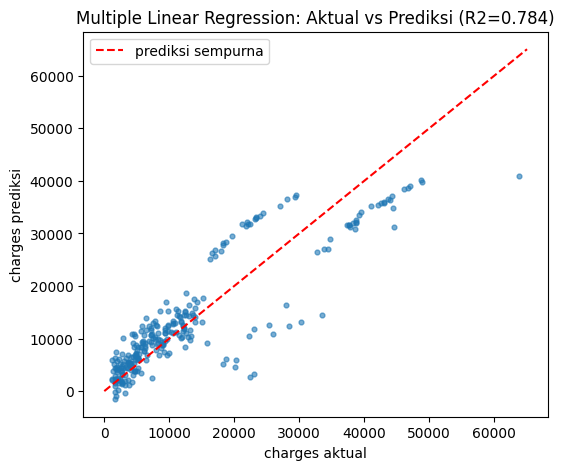

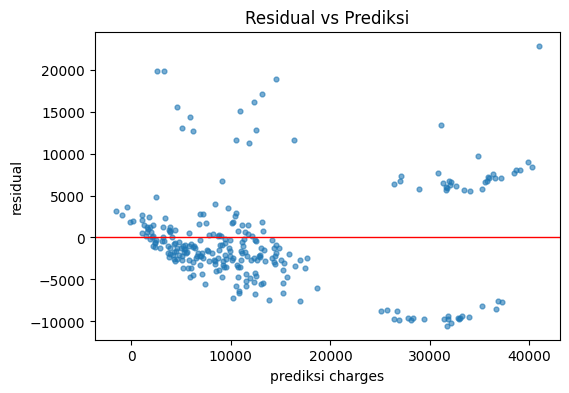

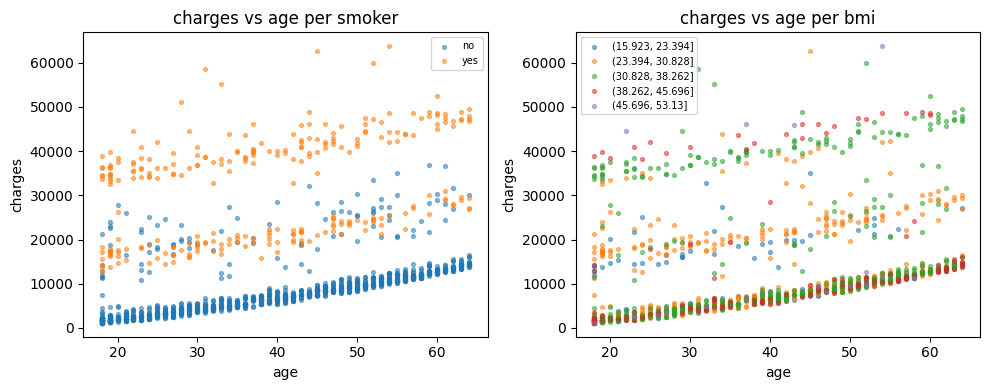

In [7]:
# --- visualisasi ---
plt.figure(figsize=(6, 5))
plt.scatter(y_te, pred, s=12, alpha=0.6)
lim = [0, max(y_te.max(), pred.max()) * 1.02]
plt.plot(lim, lim, "r--", label="prediksi sempurna")
plt.xlabel("charges aktual")
plt.ylabel("charges prediksi")
plt.title("Multiple Linear Regression: Aktual vs Prediksi (R2=%.3f)" % r2_mlr)
plt.legend()
plt.savefig(OUT / "aktual_vs_prediksi.png", dpi=120, bbox_inches="tight")

res = y_te - pred
plt.figure(figsize=(6, 4))
plt.scatter(pred, res, s=12, alpha=0.6)
plt.axhline(0, color="r", lw=1)
plt.xlabel("prediksi charges")
plt.ylabel("residual")
plt.title("Residual vs Prediksi")
plt.savefig(OUT / "residual.png", dpi=120, bbox_inches="tight")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, col in zip(ax, ["smoker", "bmi"]):
    for grp, d in df.groupby(col if col == "smoker" else pd.cut(df[col], 5),
                             observed=True):
        a.scatter(d["age"], d["charges"], s=8, alpha=0.5, label=str(grp))
    a.set_xlabel("age"); a.set_ylabel("charges"); a.set_title("charges vs age per " + col)
    a.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT / "eda_charges.png", dpi=120, bbox_inches="tight")

pd.DataFrame({"aktual": y_te, "prediksi_mlr": pred,
              "prediksi_svr": svr.predict(X_te)}).to_csv(
    OUT / "prediksi_test.csv", index=False)

In [8]:
# cek: R2 model lebih baik daripada memprediksi rata-rata
assert r2_mlr > 0 and r2_mlr > r2_svr - 0.1
print("\n[OK] R2 MLR=%.4f, SVR=%.4f, Poly2=%.4f" % (r2_mlr, r2_svr, r2_poly))


[OK] R2 MLR=0.7836, SVR=0.6099, Poly2=0.7802
